In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_parquet("newtonian_trials.pq")
mask = ~np.isinf(df["sma"])

df_soft = pd.read_parquet("softened_trials.pq")
mask_soft = ~np.isinf(df_soft["sma"])

In [26]:
def plot_pdf_wrapper(data, bins='auto', ax_pdf=None):
    """
    Plot a normalized PDF (max ~1) and ECDF for given data.
    
    Parameters
    ----------
    data : array-like
        Input 1D data.
    bins : str or int or sequence, optional
        Binning strategy for the histogram. Default 'auto' (uses numpy's automatic bin selection).
    ax_pdf, ax_ecdf : matplotlib Axes, optional
        Axes to plot on. If None, new figure and axes are created.
    """
    data = np.asarray(data)
    
    # Create axes if not provided
    if ax_pdf is None or ax_pdf is None:
        fig, ax_pdf = plt.subplots()
    
    # --- PDF ---
    counts, edges = np.histogram(data, bins=bins)
    counts = counts * 1.
    counts /= counts.max()  # scale so max ~ 1
    # Repeat counts to match step boundaries
    x = np.repeat(edges, 2)
    y = np.hstack(([0], np.repeat(counts, 2), [0]))  # drop to 0 outside range
    ax_pdf.plot(x, y)
    return ax_pdf, bins


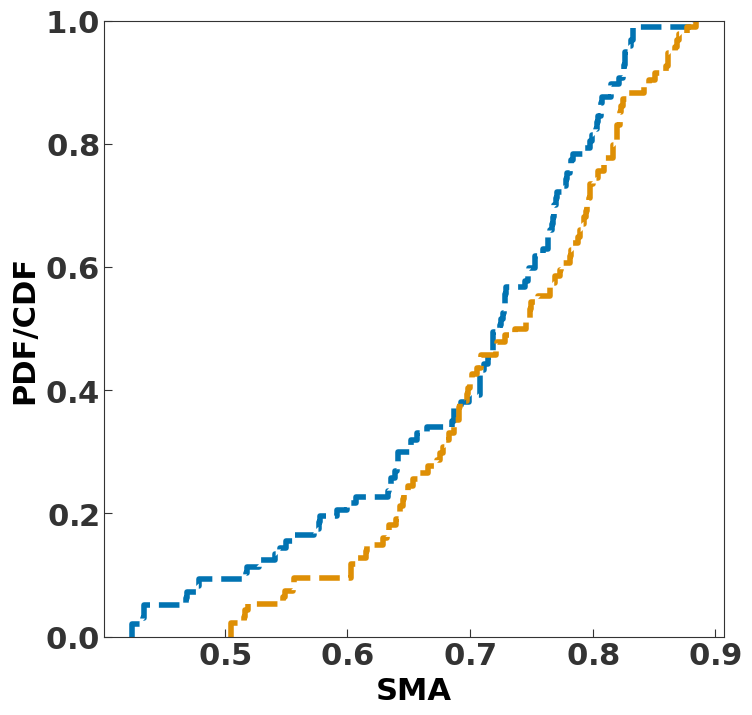

In [27]:
fig,ax = plt.subplots()
# ax.set_ylim(0, 1.1)
ax.set_xlabel("SMA")
ax.set_ylabel("PDF/CDF")

bins = "auto"
# ax_pdf, bins = plot_pdf_wrapper(df["sma"][mask], ax_pdf=ax, bins=bins)
ax.ecdf(df["sma"][mask], linestyle="--")

# ax_pdf, bins = plot_pdf_wrapper(df_soft["sma"][mask_soft], ax_pdf=ax, bins=bins)
ax.ecdf(df_soft["sma"][mask_soft], linestyle="--")


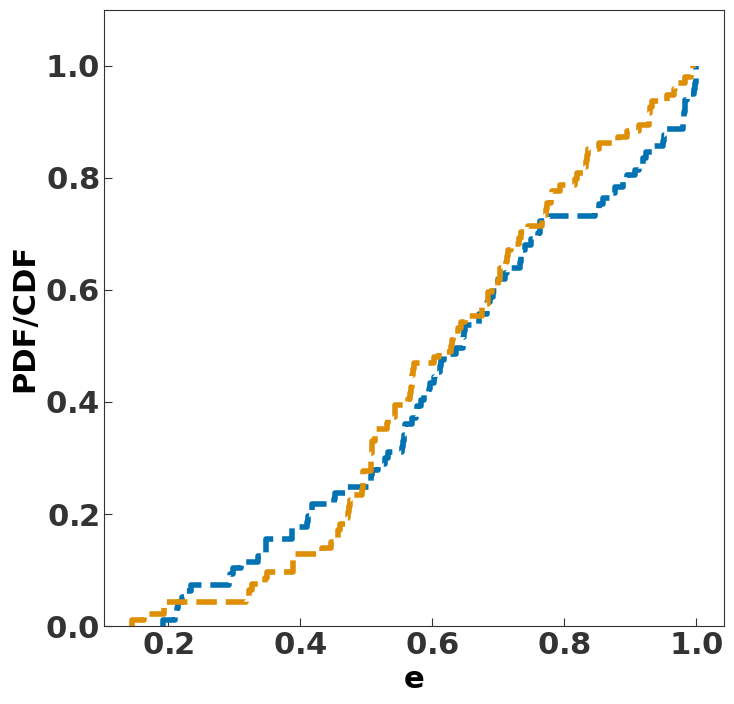

In [28]:
fig,ax = plt.subplots()
ax.set_ylim(0, 1.1)
ax.set_xlabel("e")
ax.set_ylabel("PDF/CDF")

bins = "auto"
# ax_pdf, bins = plot_pdf_wrapper(df["ecc"][mask], ax_pdf=ax, bins=bins)
ax.ecdf(df["ecc"][mask], linestyle="--")
ax.ecdf(df_soft["ecc"][mask_soft], linestyle="--")

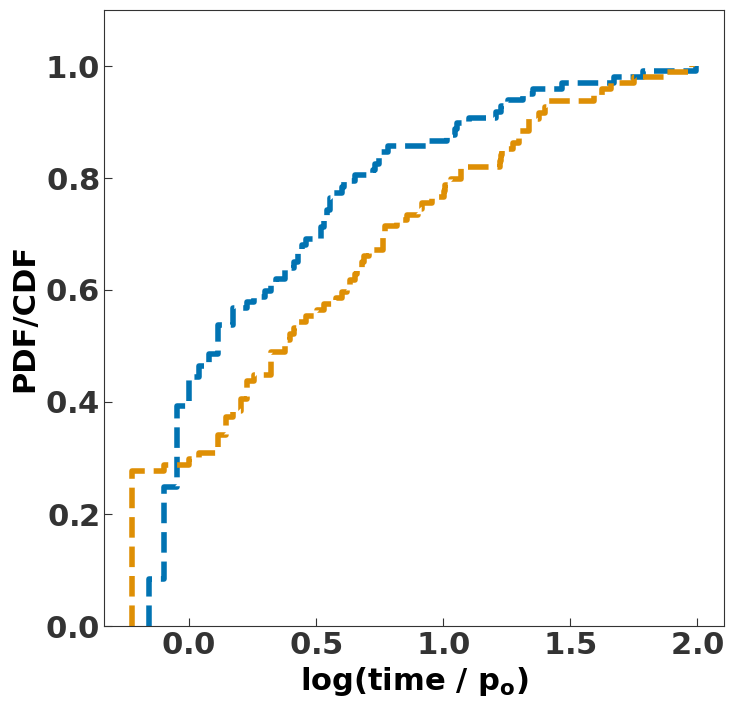

In [29]:
fig,ax = plt.subplots()
ax.set_ylim(0, 1.1)
ax.set_xlabel("log(time / $p_o$)")
ax.set_ylabel("PDF/CDF")

pin = 2 * np.pi * 1. / (2.**.5)
pout = 2 * np.pi * 10.**1.5 / (3.**.5)
##Normalizing time elapsed by the initial tertiary period...
bins="auto"
# ax_pdf, bins = plot_pdf_wrapper(np.log10(df["time"][mask] / pout), ax_pdf=ax, bins=bins)
ax.ecdf(np.log10(df["time"][mask] / pout), linestyle="--")
ax.ecdf(np.log10(df_soft["time"][mask_soft] / pout), linestyle="--")

In [ ]:
import rebound
import reboundx
import numpy as np

from starforge_mult_search.code.find_multiples_new2 import cluster, system


softening_length = 0.9
def get_state(sim):
    ##Trick to synchronize the accelerations
    ##Is there a way to force the accelerations to be recomputed??
    sim.integrate(sim.t + 1e-15 * sim.t)
    accel1 = np.array((sim.particles[0].ax, sim.particles[0].ay, sim.particles[0].az))
    accel2 = np.array((sim.particles[1].ax, sim.particles[1].ay, sim.particles[1].az))
    accel3 = np.array((sim.particles[2].ax, sim.particles[2].ay, sim.particles[2].az))
    ps = np.array([pp.xyz for pp in sim.particles])
    vs = np.array([pp.vxyz for pp in sim.particles])
    ms = np.array([pp.m for pp in sim.particles])
    ##You will have to adjust the 4th argument when you have softening(!)
    ##Systems are only grouped if we have the tidal force < 0.01 times the internal force.
    cl = cluster(ps, vs, ms, np.ones(len(ps)) * softening_length, np.array([0, 1, 2]), np.array((accel1, accel2, accel3)), tides=True, sma_order=True, tides_factor=0.01)
    return cl.systems

sim = rebound.Simulation()
# sim.softening = 0.1
sim.add(m=1)
sim.add(m=1, a=1)
sim.add(m=1e-5, a=10000, inc = 2. * np.pi / 3) 
sim.move_to_com()
# rebx = reboundx.Extras(sim)
# softened_force = rebx.load_force("softened_force")
# rebx.add_force(softened_force)
# sim.particles[0].params["softening_length"] = softening_length
# sim.particles[1].params["softening_length"] = softening_length
# sim.particles[2].params["softening_length"] = softening_length



[sfc] GN overridden to 1.0 from GN_override.txt


In [2]:
sys1 = get_state(sim)

[-1.  0.  0.] 1.0
[1. 0. 0.] 1.0
[1. 0. 0.] 1.0
[-1.  0.  0.] 1.0


In [3]:
[ss.hierarchy for ss in sys1]

[0, 1, 2]

In [72]:
sim.G

1.0